# Этап 3. Модели

Результаты получены программой src/train.py и сохранены в reports/metrics.json.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from db import connect

pd.set_option("display.width", 130, "display.max_columns", 30, "display.max_rows", 60)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
NAVY, BLUE, YELLOW, GREY = "#17358A", "#2F6FD0", "#F2C230", "#8A94A6"
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white", "savefig.dpi": 200,
                     "savefig.bbox": "tight"})


def sql(query, params=None):
    """Запрос к базе PostgreSQL: результат в виде таблицы pandas."""
    with connect() as conn:
        cur = conn.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

In [2]:
import joblib
from preprocess import CLASS_NAMES
m = json.loads((ROOT / "reports" / "metrics.json").read_text(encoding="utf-8"))
model = joblib.load(ROOT / "models" / "model.joblib")
gold = pd.read_csv(ROOT / "data" / "gold" / "offers_gold.csv", encoding="utf-8-sig")
test = gold[gold.split == "test"]
print("Признаки:", m["features"])
print("Обучение:", m["n_train"], "тест:", m["n_test"], "лучшая модель:", m["best"])

Признаки: ['area_total', 'rooms', 'floor', 'floors_total', 'built_year', 'metro_minutes', 'dist_center_km', 'latitude', 'longitude', 'renovation', 'building_type', 'metro_transport', 'okrug']
Обучение: 3982 тест: 1231 лучшая модель: Градиентный бустинг


In [3]:
# Перекрёстная проверка по домам: MAE логарифма цены
print(pd.DataFrame({k: pd.DataFrame(m[k]).T["mean"] for k in ("cv_по_умолчанию", "cv_подобранные")}).round(4).to_string())
print(pd.DataFrame(m["cv_подобранные"]).T["std"].round(4).to_string())
for name, value in m["best_params"].items():
    print(name, value)

                     cv_по_умолчанию  cv_подобранные
Базовая (медиана)             0.4296          0.4296
Линейная регрессия            0.1646          0.1646
Случайный лес                 0.1560          0.1512
Градиентный бустинг           0.1544          0.1488
Нейронная сеть                0.1532          0.1498
Базовая (медиана)      0.0188
Линейная регрессия     0.0034
Случайный лес          0.0041
Градиентный бустинг    0.0043
Нейронная сеть         0.0037
Случайный лес {'params': {'max_depth': 'None', 'max_features': '0.5', 'min_samples_leaf': '1', 'n_estimators': '300'}, 'variants': 8}
Градиентный бустинг {'params': {'learning_rate': '0.05', 'max_depth': '3', 'n_estimators': '600', 'subsample': '0.8'}, 'variants': 8}
Нейронная сеть {'params': {'alpha': '1.0', 'hidden_layer_sizes': '(128, 64)'}, 'variants': 9}


In [4]:
# Итоговые ошибки на обучающей и тестовой выборках
rows = {}
for name, r in m["results"].items():
    rows[name] = {"MAE обуч.": r["train"]["MAE"], "MAE тест": r["test"]["MAE"], "RMSE тест": r["test"]["RMSE"],
                  "MAPE обуч.": r["train"]["MAPE"], "MAPE тест": r["test"]["MAPE"], "R2 тест": r["test"]["R2"]}
pd.DataFrame(rows).T.round({"MAE обуч.": 0, "MAE тест": 0, "RMSE тест": 0, "MAPE обуч.": 1, "MAPE тест": 1, "R2 тест": 3})

,MAE обуч.,MAE тест,RMSE тест,MAPE обуч.,MAPE тест,R2 тест
Базовая (медиана),52588.0,43759.0,66893.0,40.8,39.3,-0.065
Линейная регрессия,21705.0,20590.0,41465.0,16.3,16.3,0.591
Случайный лес,6877.0,17426.0,28459.0,5.2,14.7,0.807
Градиентный бустинг,14342.0,17353.0,28622.0,11.4,14.7,0.805
Нейронная сеть,17935.0,17238.0,29079.0,13.8,14.2,0.799


                      accuracy  macro_f1  off_by_one_or_less
Базовая (медиана)        0.258     0.103               0.738
Линейная регрессия       0.686     0.688               0.991
Случайный лес            0.702     0.703               0.995
Градиентный бустинг      0.708     0.710               0.995
Нейронная сеть           0.711     0.712               0.997
Прямой классификатор     0.699     0.700               0.993
         Эконом  Средний  Комфорт  Премиум
Эконом      259       61        3        0
Средний      59      173       54        1
Комфорт       0       68      222       28
Премиум       0        2       83      218


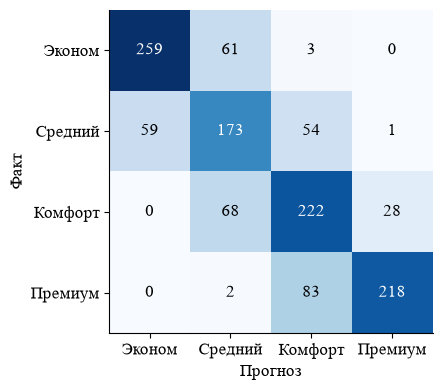

In [5]:
# Ценовой класс: точность и F1 на тесте
rows = {name: {k: r["class"][k] for k in ("accuracy", "macro_f1", "off_by_one_or_less")} for name, r in m["results"].items()}
rows["Прямой классификатор"] = {k: m["direct_classifier"][k] for k in ("accuracy", "macro_f1", "off_by_one_or_less")}
print(pd.DataFrame(rows).T.round(3).to_string())
matrix = np.array(m["results"][m["best"]]["class"]["confusion"])
print(pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_string())
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(matrix, cmap="Blues")
ax.set_xticks(range(4), CLASS_NAMES); ax.set_yticks(range(4), CLASS_NAMES)
ax.set(xlabel="Прогноз", ylabel="Факт")
for i in range(4):
    for j in range(4):
        ax.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > 120 else "black")
fig.savefig(FIG / "confusion_matrix.png")

In [6]:
# Подробности об ошибке лучшей модели и проверка самопроверки
print({k: round(v, 1) for k, v in m["best_details"].items() if isinstance(v, float)})
print("MAPE по классам:", {k: round(v, 1) for k, v in m["best_details"]["by_class_mape"].items()})
print("Самопроверка на тесте:", m.get("self_check_on_test"))

{'median_ape': 11.4, 'ape_le_10': 44.6, 'ape_gt_30': 10.0, 'under': 49.9, 'pred_mean': 109350.2, 'true_mean': 111466.0, 'true_median': 95000.0, 'train_median': 95000.0, 'coverage': 61.2}
MAPE по классам: {'Эконом': 14.5, 'Средний': 13.0, 'Комфорт': 13.2, 'Премиум': 18.1}
Самопроверка на тесте: {'норма': {'share': 84.72786352558896, 'mape': 14.09659191431125}, 'внимание': {'share': 15.272136474411047, 'mape': 18.046474179181}}


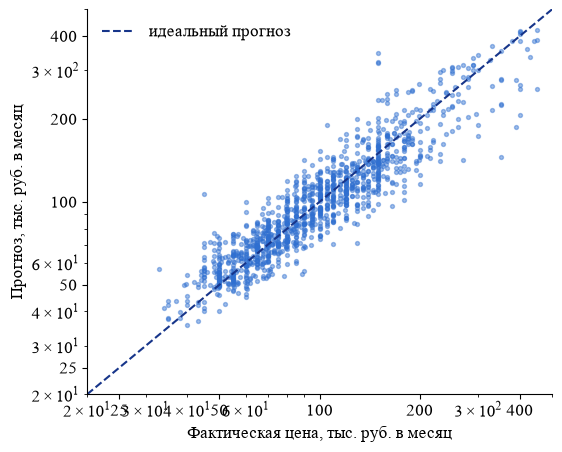

In [7]:
# Прогноз и факт на тестовой выборке
pred = np.exp(model.predict(test[m["features"]]))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(test.price / 1000, pred / 1000, s=8, alpha=.45, color=BLUE)
lim = [20, 500]
ax.plot(lim, lim, "--", color=NAVY, label="идеальный прогноз")
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Фактическая цена, тыс. руб. в месяц", ylabel="Прогноз, тыс. руб. в месяц")
ax.set_xticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"]); ax.set_yticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"])
ax.legend(frameon=False)
fig.savefig(FIG / "pred_vs_true.png")

area_total         0.1809
dist_center_km     0.1196
built_year         0.0374
renovation         0.0268
longitude          0.0202
latitude           0.0044
building_type      0.0042
floors_total       0.0041
okrug              0.0039
rooms              0.0018
floor              0.0006
metro_minutes      0.0002
metro_transport    0.0001


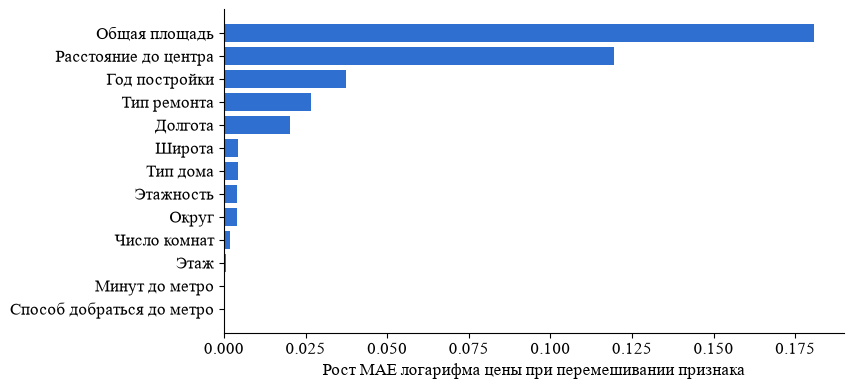

In [8]:
# Важность признаков методом перестановки
names = {"area_total": "Общая площадь", "dist_center_km": "Расстояние до центра", "built_year": "Год постройки",
         "renovation": "Тип ремонта", "longitude": "Долгота", "latitude": "Широта", "building_type": "Тип дома",
         "floors_total": "Этажность", "okrug": "Округ", "rooms": "Число комнат", "floor": "Этаж",
         "metro_minutes": "Минут до метро", "metro_transport": "Способ добраться до метро"}
imp = pd.Series(m["best_details"]["importance"])
print(imp.round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([names[k] for k in imp.index[::-1]], imp.values[::-1], color=BLUE)
ax.set(xlabel="Рост MAE логарифма цены при перемешивании признака")
fig.savefig(FIG / "importance.png")

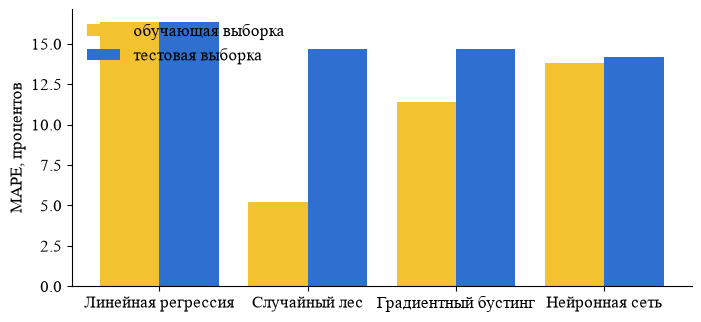

In [9]:
# Сравнение моделей
fig, ax = plt.subplots(figsize=(8, 3.6))
items = [k for k in m["results"] if not k.startswith("Базовая")]
x = np.arange(len(items))
ax.bar(x - .2, [m["results"][k]["train"]["MAPE"] for k in items], .4, label="обучающая выборка", color=YELLOW)
ax.bar(x + .2, [m["results"][k]["test"]["MAPE"] for k in items], .4, label="тестовая выборка", color=BLUE)
ax.set_xticks(x, items); ax.set_ylabel("MAPE, процентов"); ax.legend(frameon=False)
fig.savefig(FIG / "models_mape.png")

In [10]:
# Примеры прогнозов с самопроверкой (журнал прогнозов в блокноте не пополняется)
from predictor import Flat, RentPredictor
predictor = RentPredictor()
predictor.monitor.log = lambda *a, **k: None
cases = [("студия, 28 кв. м, ЮВАО", dict(area_total=28, rooms=0, floor=7, floors_total=17, built_year=2015, metro_minutes=10), predictor.resolver.by_filter("ЮВАО")),
         ("1 комн., 40 кв. м, станция Отрадное", dict(area_total=40, rooms=1, floor=5, floors_total=12, built_year=1985, metro_minutes=8, building_type="Панельный", renovation="Косметический"), predictor.resolver.by_station("Отрадное")),
         ("2 комн., 60 кв. м, 10 км от центра", dict(area_total=60, rooms=2, floor=9, floors_total=25, built_year=2018, metro_minutes=10), predictor.resolver.by_filter(distance=10)),
         ("3 комн., 90 кв. м, ЦАО", dict(area_total=90, rooms=3, floor=4, floors_total=9, built_year=2005, metro_minutes=7, renovation="Дизайнерский"), predictor.resolver.by_filter("ЦАО")),
         ("2 комн., 290 кв. м, ЦАО", dict(area_total=290, rooms=2, floor=4, floors_total=9, built_year=2005, metro_minutes=7), predictor.resolver.by_filter("ЦАО"))]
for name, values, place in cases:
    r = predictor.predict(Flat(**values), place)
    print(f"{name:38} {r['price']:9.0f} руб. {r['class_name']:8} {r['check']['status']}", [n for n, ok, _ in r["check"]["items"] if not ok])

студия, 28 кв. м, ЮВАО                     65379 руб. Эконом   норма []
1 комн., 40 кв. м, станция Отрадное        57554 руб. Эконом   норма []
2 комн., 60 кв. м, 10 км от центра        129718 руб. Комфорт  норма []
3 комн., 90 кв. м, ЦАО                    252045 руб. Премиум  внимание ['Сравнение с похожими квартирами']
2 комн., 290 кв. м, ЦАО                   362038 руб. Премиум  внимание ['Параметры в диапазоне обучающих данных', 'Совпадение с контрольной моделью', 'Сравнение с похожими квартирами']
